In [2]:
import cv2 as cv
import numpy as np

img=cv.imread('lacko.png')	 # 영상 읽기
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
canny=cv.Canny(gray,100,200) 

contour,hierarchy=cv.findContours(canny,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)

lcontour=[]   
for i in range(len(contour)):
    if contour[i].shape[0]>100:	# 길이가 100보다 크면
        lcontour.append(contour[i])
    
cv.drawContours(img,lcontour,-1,(0,255,0),3)
             
cv.imshow('Original with contours',img)    
cv.imshow('Canny',canny)    

cv.waitKey()
cv.destroyAllWindows()

In [3]:
import cv2 as cv 

img=cv.imread('./ch4/apples.jpg')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

apples=cv.HoughCircles(gray,cv.HOUGH_GRADIENT,1,200,param1=150,param2=20,minRadius=50,maxRadius=120)

for i in apples[0]: 
    cv.circle(img,(int(i[0]),int(i[1])),int(i[2]),(255,0,0),2)

cv.imshow('Apple detection',img)  

cv.waitKey()
cv.destroyAllWindows()

In [16]:
import cv2 as cv 

img=cv.imread('./grape.jpeg')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

apples=cv.HoughCircles(gray,cv.HOUGH_GRADIENT,1,20,param1=100,param2=25,minRadius=10,maxRadius=40)

for i in apples[0]: 
    cv.circle(img,(int(i[0]),int(i[1])),int(i[2]),(255,0,0),2)

cv.imshow('Apple detection',img)  

cv.waitKey()
cv.destroyAllWindows()

In [4]:
import cv2 as cv 

img=cv.imread('./nemo.jpg')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

apples=cv.HoughCircles(gray,cv.HOUGH_GRADIENT,1,25,param1=100,param2=25,minRadius=10,maxRadius=40)

for i in apples[0]: 
    cv.circle(img,(int(i[0]),int(i[1])),int(i[2]),(255,0,0),2)

cv.imshow('Apple detection',img)  

cv.waitKey()
cv.destroyAllWindows()

In [5]:
import skimage
import numpy as np
import cv2 as cv

img=skimage.data.coffee()
cv.imshow('Coffee image',cv.cvtColor(img,cv.COLOR_RGB2BGR))

slic1=skimage.segmentation.slic(img,compactness=20,n_segments=600)
sp_img1=skimage.segmentation.mark_boundaries(img,slic1)
sp_img1=np.uint8(sp_img1*255.0)

slic2=skimage.segmentation.slic(img,compactness=40,n_segments=600)
sp_img2=skimage.segmentation.mark_boundaries(img,slic2)
sp_img2=np.uint8(sp_img2*255.0)

cv.imshow('Super pixels (compact 20)',cv.cvtColor(sp_img1,cv.COLOR_RGB2BGR))
cv.imshow('Super pixels (compact 40)',cv.cvtColor(sp_img2,cv.COLOR_RGB2BGR))

cv.waitKey()
cv.destroyAllWindows()

In [6]:
import skimage
import numpy as np
import cv2 as cv

img=cv.imread('./simple.jpg')
cv.imshow('Coffee image',cv.cvtColor(img,cv.COLOR_RGB2BGR))

slic1=skimage.segmentation.slic(img,compactness=10,n_segments=600)
sp_img1=skimage.segmentation.mark_boundaries(img,slic1)
sp_img1=np.uint8(sp_img1*255.0)

slic2=skimage.segmentation.slic(img,compactness=40,n_segments=600)
sp_img2=skimage.segmentation.mark_boundaries(img,slic2)
sp_img2=np.uint8(sp_img2*255.0)

cv.imshow('Super pixels (compact 20)',cv.cvtColor(sp_img1,cv.COLOR_RGB2BGR))
cv.imshow('Super pixels (compact 40)',cv.cvtColor(sp_img2,cv.COLOR_RGB2BGR))

cv.waitKey()
cv.destroyAllWindows()

In [13]:
import skimage
import numpy as np
import cv2 as cv
import time

coffee=skimage.data.coffee()

start=time.time()
slic=skimage.segmentation.slic(coffee,compactness=20,n_segments=600,start_label=1)
g=skimage.graph.rag_mean_color(coffee,slic,mode='similarity') 
ncut=skimage.graph.cut_normalized(slic,g)	# 정규화 절단
print(coffee.shape,' Coffee 영상을 분할하는데 ',time.time()-start,'초 소요')

marking=skimage.segmentation.mark_boundaries(coffee,ncut)
ncut_coffee=np.uint8(marking*255.0)

cv.imshow('Normalized cut',cv.cvtColor(ncut_coffee,cv.COLOR_RGB2BGR))  

cv.waitKey()
cv.destroyAllWindows()

(400, 600, 3)  Coffee 영상을 분할하는데  1.6400291919708252 초 소요


In [18]:
import skimage
import numpy as np
import cv2 as cv
import time

img=cv.imread('./parkj.jpg')

start=time.time()
slic=skimage.segmentation.slic(img,compactness=20,n_segments=600,start_label=1)
g=skimage.graph.rag_mean_color(img,slic,mode='similarity') 
ncut=skimage.graph.cut_normalized(slic,g)	# 정규화 절단
print(coffee.shape,' 사진 분할 시간 ',time.time()-start,'초 소요')

marking=skimage.segmentation.mark_boundaries(img,ncut)
ncut_coffee=np.uint8(marking*255.0)

cv.imshow('Normalized cut',cv.cvtColor(ncut_coffee,cv.COLOR_RGB2BGR))  

cv.waitKey()
cv.destroyAllWindows()

(400, 600, 3)  사진 분할 시간  31.639694452285767 초 소요


(237, 236, 3)  사진 분할 시간  0.7056906223297119 초 소요


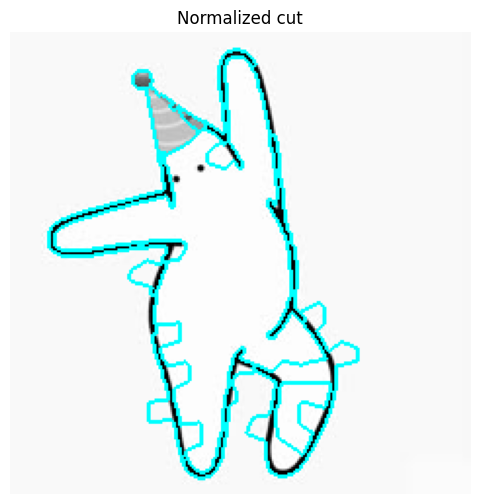

In [22]:
import skimage
import numpy as np
import cv2 as cv
import time
import matplotlib.pyplot as plt

img = cv.imread('./simple.jpg')

if img is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

start = time.time()
slic = skimage.segmentation.slic(img, compactness=20, n_segments=600, start_label=1)
g = skimage.graph.rag_mean_color(img, slic, mode='similarity') 
ncut = skimage.graph.cut_normalized(slic, g)   # 정규화 절단

print(img.shape, ' 사진 분할 시간 ', time.time() - start, '초 소요')

marking = skimage.segmentation.mark_boundaries(img, ncut)
ncut_coffee = np.uint8(marking * 255.0)

# OpenCV의 BGR 채널을 Matplotlib의 RGB 채널로 변환
img_rgb = cv.cvtColor(ncut_coffee, cv.COLOR_BGR2RGB)

# Matplotlib을 이용해 출력창 내부(Inline)에 표시
plt.figure(figsize=(8, 6)) # 이미지 출력 크기 설정
plt.imshow(img_rgb)
plt.axis('off') # 눈금 표시 제거
plt.title('Normalized cut')
plt.show() # 별도 창 없이 출력창에 사진 표시

In [25]:
import cv2 as cv 
import numpy as np

img=cv.imread('./ch4/soccer.jpg')	# 영상 읽기
img_show=np.copy(img)		# 붓 칠을 디스플레이할 목적의 영상

mask=np.zeros((img.shape[0],img.shape[1]),np.uint8) 
mask[:,:]=cv.GC_PR_BGD		# 모든 화소를 배경일 것 같음으로 초기화

BrushSiz=9				# 붓의 크기
LColor,RColor=(255,0,0),(0,0,255)	# 파란색(물체)과 빨간색(배경)

def painting(event,x,y,flags,param):
    if event==cv.EVENT_LBUTTONDOWN:   
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)	# 왼쪽 버튼 클릭하면 파란색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_RBUTTONDOWN: 
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하면 빨간색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_LBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)# 왼쪽 버튼 클릭하고 이동하면 파란색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_RBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하고 이동하면 빨간색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)

    cv.imshow('Painting',img_show)
    
cv.namedWindow('Painting')
cv.setMouseCallback('Painting',painting)

while(True):				# 붓 칠을 끝내려면 'q' 키를 누름
    if cv.waitKey(1)==ord('q'): 
        break

# 여기부터 GrabCut 적용하는 코드
background=np.zeros((1,65),np.float64)	# 배경 히스토그램 0으로 초기화
foreground=np.zeros((1,65),np.float64)	# 물체 히스토그램 0으로 초기화

cv.grabCut(img,mask,None,background,foreground,5,cv.GC_INIT_WITH_MASK)
mask2=np.where((mask==cv.GC_BGD)|(mask==cv.GC_PR_BGD),0,1).astype('uint8')
grab=img*mask2[:,:,np.newaxis]
cv.imshow('Grab cut image',grab)  

cv.waitKey()
cv.destroyAllWindows()

KeyboardInterrupt: 

In [ ]:
import cv2 as cv 
import numpy as np

img=cv.imread('./ch4/soccer.jpg')	# 영상 읽기
img_show=np.copy(img)		# 붓 칠을 디스플레이할 목적의 영상

mask=np.zeros((img.shape[0],img.shape[1]),np.uint8) 
mask[:,:]=cv.GC_PR_BGD		# 모든 화소를 배경일 것 같음으로 초기화

BrushSiz=9				# 붓의 크기
LColor,RColor=(255,0,0),(0,0,255)	# 파란색(물체)과 빨간색(배경)

def painting(event,x,y,flags,param):
    if event==cv.EVENT_LBUTTONDOWN:   
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)	# 왼쪽 버튼 클릭하면 파란색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_RBUTTONDOWN: 
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하면 빨간색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_LBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)# 왼쪽 버튼 클릭하고 이동하면 파란색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_RBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하고 이동하면 빨간색
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)

    cv.imshow('Painting',img_show)
    
cv.namedWindow('Painting')
cv.setMouseCallback('Painting',painting)

while(True):				# 붓 칠을 끝내려면 'q' 키를 누름
    if cv.waitKey(1)==ord('q'): 
        break

# 여기부터 GrabCut 적용하는 코드
background=np.zeros((1,65),np.float64)	# 배경 히스토그램 0으로 초기화
foreground=np.zeros((1,65),np.float64)	# 물체 히스토그램 0으로 초기화

cv.grabCut(img,mask,None,background,foreground,5,cv.GC_INIT_WITH_MASK)
mask2=np.where((mask==cv.GC_BGD)|(mask==cv.GC_PR_BGD),0,1).astype('uint8')
grab=img*mask2[:,:,np.newaxis]
cv.imshow('Grab cut image',grab)  

cv.waitKey()
cv.destroyAllWindows()

In [2]:
import cv2 as cv 
import numpy as np

img=cv.imread('./we.jpg')	# 영상 읽기
img_show=np.copy(img)		# 붓 칠을 디스플레이할 목적의 영상

#이미지와 동일한 가로세로 크기의 단일 채널 마스크 2차원 배열 생성
mask=np.zeros((img.shape[0],img.shape[1]),np.uint8) 
# 생성한 배열에 모든 화소를 배경일 것 같음으로 초기화
mask[:,:]=cv.GC_PR_BGD

BrushSiz=9				# 붓의 크기
LColor,RColor=(255,0,0),(0,0,255)	# 파란색(물체)과 빨간색(배경)

def painting(event,x,y,flags,param):
    if event==cv.EVENT_LBUTTONDOWN:   
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)	# 왼쪽 버튼 클릭하면 원으로 파란색
        #해당 위치를 물체가 있는 위치로 설정
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_RBUTTONDOWN: 
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하면 빨간색
        # 해당 위치를 배경이 있는 위치로 설정
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_LBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,LColor,-1)   # 왼쪽 버튼 클릭하고 이동하면 파란색
        # 해당 위치를 물체 영역으로 설정
        cv.circle(mask,(x,y),BrushSiz,cv.GC_FGD,-1)
    elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_RBUTTON:
        cv.circle(img_show,(x,y),BrushSiz,RColor,-1)	# 오른쪽 버튼 클릭하고 이동하면 빨간색
        # 해당 위치를 배경으로 설정
        cv.circle(mask,(x,y),BrushSiz,cv.GC_BGD,-1)
#사진 출력
    cv.imshow('Painting',img_show)
# 윈도우 창이름    
cv.namedWindow('Painting')
# 마우스 이벤트가 발생하면 위에 미리 선언해둔 함수와 연결
cv.setMouseCallback('Painting',painting)

while(True):				# 붓 칠을 끝내려면 'q' 키를 누름
    if cv.waitKey(1)==ord('q'): 
        break

# 여기부터 GrabCut 적용하는 코드
background=np.zeros((1,65),np.float64)	# 배경 히스토그램 0으로 초기화
foreground=np.zeros((1,65),np.float64)	# 물체 히스토그램 0으로 초기화

#원본 이미지, 마스크 정보, 사각형 모드 none, 알고리즘 반복횟수5, 사용자가 입력한 mask정보를 기반으로 분할 시작
cv.grabCut(img,mask,None,background,foreground,5,cv.GC_INIT_WITH_MASK)
# 0 확실히 배경, 1 확실히 물체, 2는 배경일것같음 , 3은 문체일것같음(2,3은 함수가 자동으로 써넣음) 해서 다시 0과 1로 나누어서 값 저장
mask2=np.where((mask==cv.GC_BGD)|(mask==cv.GC_PR_BGD),0,1).astype('uint8')

#2차원 마스크를 3차원으로 확장해서 기본 이미지와 곱한다. 배경영역은 검은색이 되고 물체는 그대로 남는다.
grab=img*mask2[:,:,np.newaxis]
#이미지 출력
cv.imshow('Grab cut image',grab)  
#키 입력이 있을때까지 대기하다가 창 종료
cv.waitKey()
cv.destroyAllWindows()

KeyboardInterrupt: 

In [1]:
import skimage
import numpy as np
import cv2 as cv

orig=skimage.data.horse()
img=255-np.uint8(orig)*255
cv.imshow('Horse',img)

contours,hierarchy=cv.findContours(img,cv.RETR_EXTERNAL,cv.CHAIN_APPROX_NONE)

img2=cv.cvtColor(img,cv.COLOR_GRAY2BGR)		# 컬러 디스플레이용 영상
cv.drawContours(img2,contours,-1,(255,0,255),2)
cv.imshow('Horse with contour',img2)

contour=contours[0]

m=cv.moments(contour)				# 몇 가지 특징 
area=cv.contourArea(contour)
cx,cy=m['m10']/m['m00'],m['m01']/m['m00']
perimeter=cv.arcLength(contour,True)
roundness=(4.0*np.pi*area)/(perimeter*perimeter)
print('면적=',area,'\n중점=(',cx,',',cy,')','\n둘레=',perimeter,'\n둥근 정도=',roundness)

img3=cv.cvtColor(img,cv.COLOR_GRAY2BGR)		# 컬러 디스플레이용 영상

contour_approx=cv.approxPolyDP(contour,8,True)	# 직선 근사
cv.drawContours(img3,[contour_approx],-1,(0,255,0),2)

hull=cv.convexHull(contour)			# 볼록 헐
hull=hull.reshape(1,hull.shape[0],hull.shape[2])
cv.drawContours(img3,hull,-1,(0,0,255),2)

cv.imshow('Horse with line segments and convex hull',img3)

cv.waitKey()
cv.destroyAllWindows()

면적= 42390.0 
중점=( 187.72464024534088 , 144.43640402610677 ) 
둘레= 2296.7291333675385 
둥근 정도= 0.1009842680321435


In [9]:
import skimage
import numpy as np
import cv2 as cv

orig = cv.imread('./nsimple.png')

if orig is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

gray = cv.cvtColor(orig, cv.COLOR_BGR2GRAY)

# [핵심] 반전 이진화(THRESH_BINARY_INV) 사용!
# 흰색 배경 -> 검은색(0)으로 변경
# 검은색 캐릭터 -> 흰색(255)으로 변경
_, img = cv.threshold(gray, 127, 255, cv.THRESH_BINARY_INV)

cv.imshow('Horse', img)

# 윤곽선 검출
contours, hierarchy = cv.findContours(img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

img2 = cv.cvtColor(img, cv.COLOR_GRAY2BGR)     # 컬러 디스플레이용 영상
cv.drawContours(img2, contours, -1, (255, 0, 255), 2)
cv.imshow('Horse with contour', img2)

# 가장 면적이 큰 윤곽선(캐릭터) 선택
contour = max(contours, key=cv.contourArea)

# 모멘트 및 특징 계산
m = cv.moments(contour)               
area = cv.contourArea(contour)
cx, cy = m['m10'] / m['m00'], m['m01'] / m['m00']
perimeter = cv.arcLength(contour, True)
roundness = (4.0 * np.pi * area) / (perimeter * perimeter)
print('면적 =', area, '\n중점 = (', cx, ',', cy, ')', '\n둘레 =', perimeter, '\n둥근 정도 =', roundness)

img3 = cv.cvtColor(img, cv.COLOR_GRAY2BGR)     # 컬러 디스플레이용 영상

# 다각형 근사 (초록색)
contour_approx = cv.approxPolyDP(contour, 8, True)  
cv.drawContours(img3, [contour_approx], -1, (0, 255, 0), 2)

# 볼록 헐 (빨간색)
hull = cv.convexHull(contour)         
cv.drawContours(img3, [hull], -1, (0, 0, 255), 2)

cv.imshow('Horse with line segments and convex hull', img3)

cv.waitKey(0)
cv.destroyAllWindows()

면적 = 74030.5 
중점 = ( 244.33960552294883 , 266.36445113838215 ) 
둘레 = 1904.5209826231003 
둥근 정도 = 0.25647735314600506


In [13]:
import cv2 as cv 

img=cv.imread('./coin.jpeg')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

apples=cv.HoughCircles(gray,cv.HOUGH_GRADIENT,1,30,param1=100,param2=25,minRadius=10,maxRadius=40)

for i in apples[0]: 
    cv.circle(img,(int(i[0]),int(i[1])),int(i[2]),(255,0,0),2)

cv.imshow('Coin',img)  

cv.waitKey()
cv.destroyAllWindows()

찾은 동전의 개수: 12개


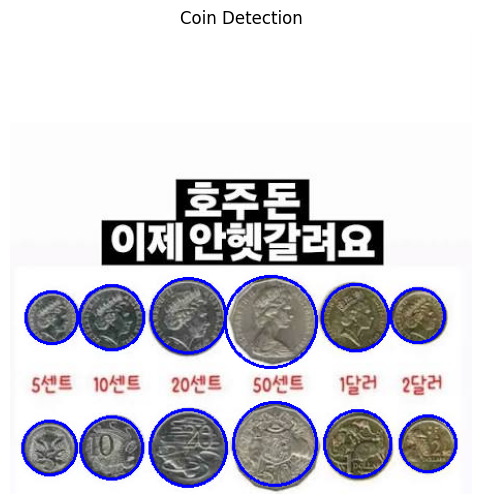

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 읽기
img = cv.imread('./coin.jpeg')

if img is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 노이즈 제거를 위해 블러링 적용
blurred = cv.GaussianBlur(gray, (7, 7), 2)

# 허프 원 변환
#블러링 적용한값, 원 검출 알고리즘
coins = cv.HoughCircles(
    blurred, 
    cv.HOUGH_GRADIENT, 
    #입력 이미지와 동일한 해상도
    dp=1,
    #검출한 원들 중심점 간 최소거리 
    minDist=40, 
    #경계선 추출 정도
    param1=100, 
    #원의 중심 결정
    param2=32, 
    # 최소 원 둘레
    minRadius=20, 
    maxRadius=45
)

count = 0

if coins is not None:
    coins = np.uint16(np.around(coins))
    count = len(coins[0])  # 검출된 동전수 저장
    
    for i in coins[0, :]:
        # 동전 테두리 (파란색)
        cv.circle(img, (i[0], i[1]), i[2], (255, 0, 0), 2)

    print(f"찾은 동전의 개수: {count}개")
else:
    print("동전을 찾지 못했습니다.")

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.axis('off')
plt.title('Coin Detection')
plt.show()

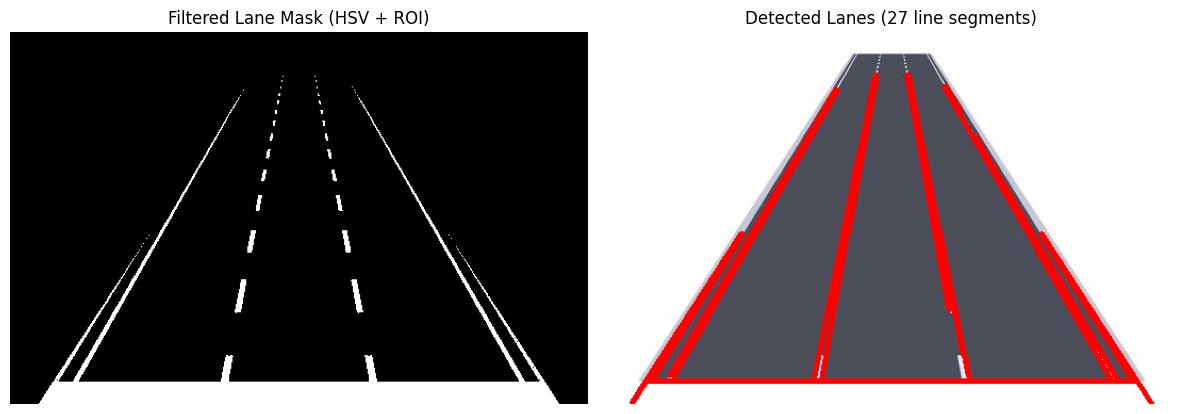

In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 읽기
img = cv.imread('./roadn.png') # 제시된 도로 이미지

if img is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

height, width = img.shape[:2]

# 2. HSV 색상 공간에서 흰색 차선 필터링
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# 흰색 영역 범위 (밝기 V값이 높고 채도 S가 낮음)
lower_white = np.array([0, 0, 200])
upper_white = np.array([180, 40, 255])
white_mask = cv.inRange(hsv, lower_white, upper_white)

# 3. ROI (도로 사다리꼴 영역) 지정
roi_mask = np.zeros_like(white_mask)
roi_corners = np.array([[
    (int(width * 0.05), height),                # 좌측 하단
    (int(width * 0.42), int(height * 0.12)),    # 좌측 상단 (소실점 부근)
    (int(width * 0.58), int(height * 0.12)),    # 우측 상단
    (int(width * 0.95), height)                 # 우측 하단
]], dtype=np.int32)

cv.fillPoly(roi_mask, roi_corners, 255)

# 흰색 마스크와 ROI 마스크 결합
target_mask = cv.bitwise_and(white_mask, roi_mask)

# 4. Canny 에지 검출
edges = cv.Canny(target_mask, 50, 150)

# 5. 확률적 허프 선 변환 (HoughLinesP)
# minLineLength: 선의 최소 길이, maxLineGap: 점선 사이 연결 허용 간격
lines = cv.HoughLinesP(
    edges, 
    rho=1, 
    theta=np.pi/180, 
    threshold=20, 
    minLineLength=15, 
    maxLineGap=40
)

# 6. 검출된 차선 시각화 (원본 이미지 복사본에 그리기)
result = img.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.ravel()
        # 빨간색 두꺼운 선으로 검출된 차선 그리기 (BGR: (0, 0, 255))
        cv.line(result, (x1, y1), (x2, y2), (0, 0, 255), 3)

# 7. Matplotlib으로 마스킹/에지 과정과 최종 결과 비교 출력
target_rgb = cv.cvtColor(target_mask, cv.COLOR_GRAY2RGB)
result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(target_rgb)
plt.title('Filtered Lane Mask (HSV + ROI)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title(f'Detected Lanes ({len(lines) if lines is not None else 0} line segments)')
plt.axis('off')

plt.tight_layout()
plt.show()

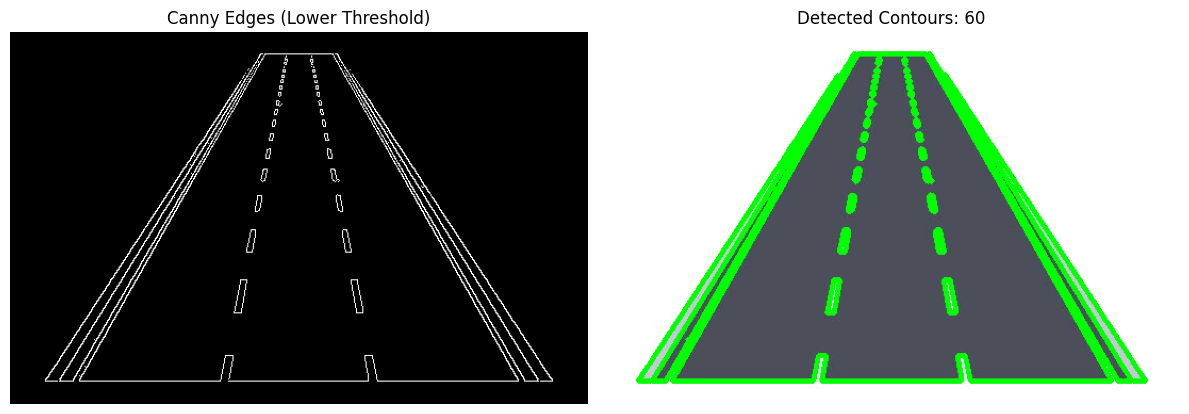

In [ ]:
import cv2 as cv
import numpy as np

img=cv.imread('roadn.png')	 # 영상 읽기
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
canny=cv.Canny(gray,50,150) 

contour,hierarchy=cv.findContours(canny,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)

lcontour=[]   
for i in range(len(contour)):
    if contour[i].shape[0]>5:
        lcontour.append(contour[i])
    
cv.drawContours(img,lcontour,-1,(0,255,0),3)
             
result = img.copy()
cv.drawContours(result, lcontour, -1, (0, 255, 0), 2) # 초록색 윤곽선

# 7. Matplotlib 시각화 (BGR -> RGB 변환)
result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

# Canny 에지 결과
plt.subplot(1, 2, 1)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edges (Lower Threshold)')
plt.axis('off')

# 윤곽선 검출 최종 결과
plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title(f'Detected Contours: {len(lcontour)}')
plt.axis('off')

plt.tight_layout()
plt.show()

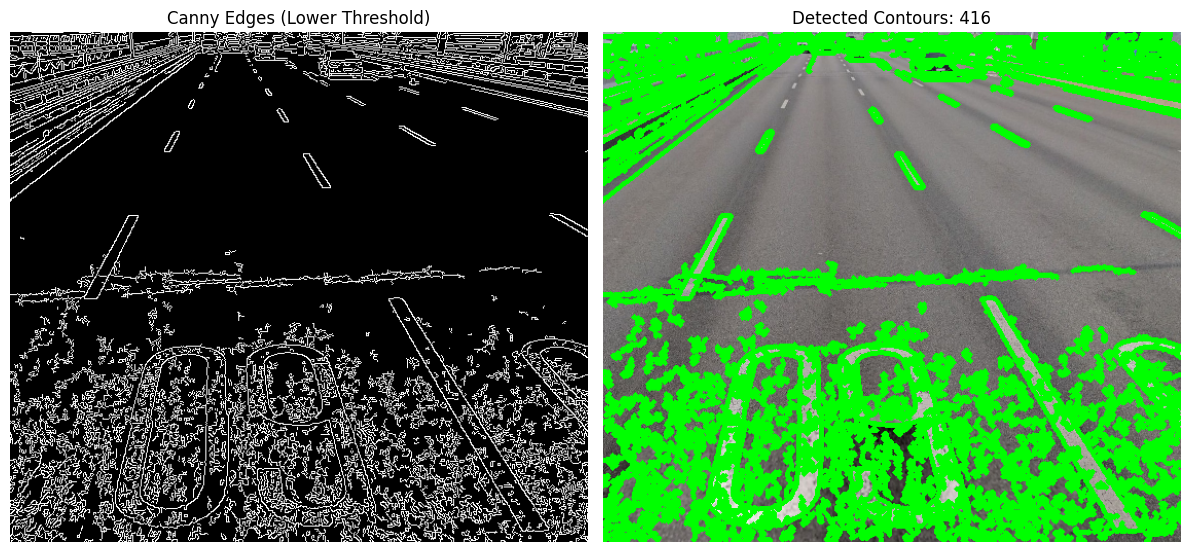

In [11]:
import cv2 as cv
import numpy as np

img=cv.imread('road.png')	 # 영상 읽기
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
canny=cv.Canny(gray,50,150) 

contour,hierarchy=cv.findContours(canny,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)

lcontour=[]   
for i in range(len(contour)):
    if contour[i].shape[0]>30:
        lcontour.append(contour[i])
    
cv.drawContours(img,lcontour,-1,(0,255,0),3)
             
result = img.copy()
cv.drawContours(result, lcontour, -1, (0, 255, 0), 2) # 초록색 윤곽선

# 7. Matplotlib 시각화 (BGR -> RGB 변환)
result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

# Canny 에지 결과
plt.subplot(1, 2, 1)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edges (Lower Threshold)')
plt.axis('off')

# 윤곽선 검출 최종 결과
plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title(f'Detected Contours: {len(lcontour)}')
plt.axis('off')

plt.tight_layout()
plt.show()

총 검출된 객체 수: 11개
[객체 #1]
 - 면적: 6579.0
 - 둘레: 392.0
 - 중심점: (314.5, 408.5)
 - 둥근 정도(원형도): 0.5380

[객체 #2]
 - 면적: 19704.0
 - 둘레: 668.0
 - 중심점: (738.5, 417.2)
 - 둥근 정도(원형도): 0.5549

[객체 #3]
 - 면적: 7872.0
 - 둘레: 424.0
 - 중심점: (197.0, 347.0)
 - 둥근 정도(원형도): 0.5503

[객체 #4]
 - 면적: 4255.0
 - 둘레: 304.0
 - 중심점: (675.5, 196.5)
 - 둥근 정도(원형도): 0.5786

[객체 #5]
 - 면적: 3712.0
 - 둘레: 314.0
 - 중심점: (780.0, 144.5)
 - 둥근 정도(원형도): 0.4731

[객체 #6]
 - 면적: 4515.0
 - 둘레: 328.0
 - 중심점: (423.5, 144.5)
 - 둥근 정도(원형도): 0.5274

[객체 #7]
 - 면적: 3036.0
 - 둘레: 310.0
 - 중심점: (781.0, 94.5)
 - 둥근 정도(원형도): 0.3970

[객체 #8]
 - 면적: 16632.0
 - 둘레: 483.6
 - 중심점: (196.0, 133.5)
 - 둥근 정도(원형도): 0.8937

[객체 #9]
 - 면적: 5280.0
 - 둘레: 386.0
 - 중심점: (589.5, 132.0)
 - 둥근 정도(원형도): 0.4453

[객체 #10]
 - 면적: 7296.0
 - 둘레: 460.0
 - 중심점: (877.0, 142.0)
 - 둥근 정도(원형도): 0.4333

[객체 #11]
 - 면적: 10622.0
 - 둘레: 546.0
 - 중심점: (332.5, 148.0)
 - 둥근 정도(원형도): 0.4477



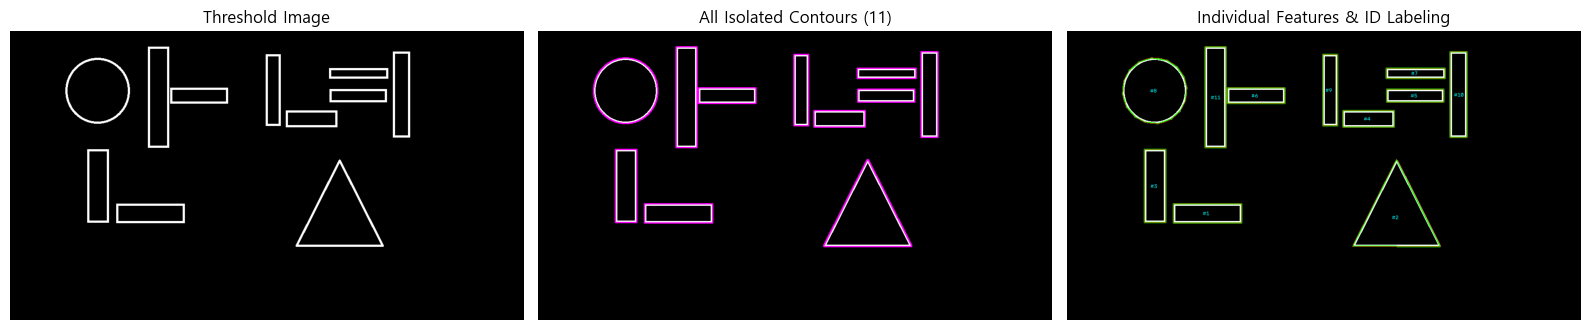

In [21]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# 1. 이미지 읽기 및 전처리
orig = cv.imread('./hi.png')

if orig is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

gray = cv.cvtColor(orig, cv.COLOR_BGR2GRAY)

# 2. 반전 이진화
_, img = cv.threshold(gray, 127, 255, cv.THRESH_BINARY_INV)

# 3. 모든 독립된 객체의 윤곽선 검출 (RETR_EXTERNAL)
contours, hierarchy = cv.findContours(img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

img_contours = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
img_features = cv.cvtColor(img, cv.COLOR_GRAY2BGR)

print(f"총 검출된 객체 수: {len(contours)}개\n" + "="*40)

# 4. 반복문을 통한 개별 객체 분리 및 분석
for idx, contour in enumerate(contours):
    # 너무 작은 노이즈 스킵
    area = cv.contourArea(contour)
    if area < 10:
        continue

    # 기하학적 특징 계산
    m = cv.moments(contour)
    cx, cy = (m['m10'] / m['m00'], m['m01'] / m['m00']) if m['m00'] != 0 else (0, 0)
    perimeter = cv.arcLength(contour, True)
    roundness = (4.0 * np.pi * area) / (perimeter * perimeter) if perimeter > 0 else 0

    print(f"[객체 #{idx + 1}]")
    print(f" - 면적: {area:.1f}")
    print(f" - 둘레: {perimeter:.1f}")
    print(f" - 중심점: ({cx:.1f}, {cy:.1f})")
    print(f" - 둥근 정도(원형도): {roundness:.4f}\n")

    # [화면 2] 분홍색 개별 윤곽선 그리기
    cv.drawContours(img_contours, [contour], -1, (255, 0, 255), 2)

    # [화면 3] 개별 다각형 근사(초록) & 볼록 헐(빨강) 시각화
    approx = cv.approxPolyDP(contour, 4, True)
    cv.drawContours(img_features, [approx], -1, (0, 255, 0), 2)

    hull = cv.convexHull(contour)
    cv.drawContours(img_features, [hull], -1, (0, 0, 255), 1)

    # 각 객체 중심에 번호(ID) 표기
    cv.putText(img_features, f"#{idx+1}", (int(cx) - 10, int(cy) + 5),
               cv.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1)

# 5. Matplotlib 시각화
img_rgb = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
img_contours_rgb = cv.cvtColor(img_contours, cv.COLOR_BGR2RGB)
img_features_rgb = cv.cvtColor(img_features, cv.COLOR_BGR2RGB)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Threshold Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_contours_rgb)
plt.title(f'All Isolated Contours ({len(contours)})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_features_rgb)
plt.title('Individual Features & ID Labeling')
plt.axis('off')

plt.tight_layout()
plt.show()

총 검출된 객체 수: 11개
[객체 #1]
 - 면적: 6579.0
 - 둘레: 392.0
 - 중심점: (314.5, 408.5)
 - 둥근 정도(원형도): 0.5380

[객체 #2]
 - 면적: 19704.0
 - 둘레: 668.0
 - 중심점: (738.5, 417.2)
 - 둥근 정도(원형도): 0.5549

[객체 #3]
 - 면적: 7872.0
 - 둘레: 424.0
 - 중심점: (197.0, 347.0)
 - 둥근 정도(원형도): 0.5503

[객체 #4]
 - 면적: 4255.0
 - 둘레: 304.0
 - 중심점: (675.5, 196.5)
 - 둥근 정도(원형도): 0.5786

[객체 #5]
 - 면적: 3712.0
 - 둘레: 314.0
 - 중심점: (780.0, 144.5)
 - 둥근 정도(원형도): 0.4731

[객체 #6]
 - 면적: 4515.0
 - 둘레: 328.0
 - 중심점: (423.5, 144.5)
 - 둥근 정도(원형도): 0.5274

[객체 #7]
 - 면적: 3036.0
 - 둘레: 310.0
 - 중심점: (781.0, 94.5)
 - 둥근 정도(원형도): 0.3970

[객체 #8]
 - 면적: 16632.0
 - 둘레: 483.6
 - 중심점: (196.0, 133.5)
 - 둥근 정도(원형도): 0.8937

[객체 #9]
 - 면적: 5280.0
 - 둘레: 386.0
 - 중심점: (589.5, 132.0)
 - 둥근 정도(원형도): 0.4453

[객체 #10]
 - 면적: 7296.0
 - 둘레: 460.0
 - 중심점: (877.0, 142.0)
 - 둥근 정도(원형도): 0.4333

[객체 #11]
 - 면적: 10622.0
 - 둘레: 546.0
 - 중심점: (332.5, 148.0)
 - 둥근 정도(원형도): 0.4477



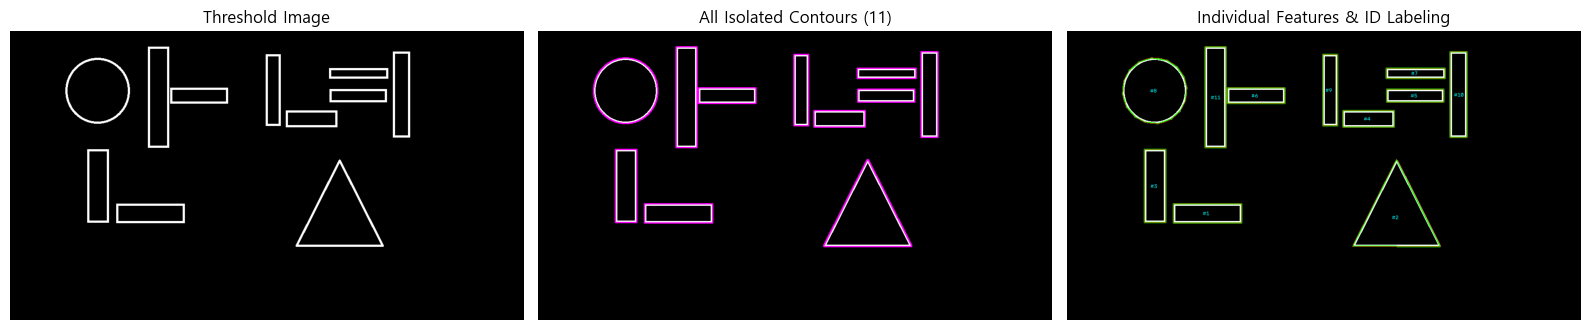

In [26]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# 1. 이미지 읽기 및 전처리
orig = cv.imread('./hi.png')

if orig is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

gray = cv.cvtColor(orig, cv.COLOR_BGR2GRAY)

# 2. 반전 이진화
_, img = cv.threshold(gray, 127, 255, cv.THRESH_BINARY_INV)

# 3. 모든 독립된 객체의 윤곽선 검출 (RETR_EXTERNAL)
contours, hierarchy = cv.findContours(img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

img_contours = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
img_features = cv.cvtColor(img, cv.COLOR_GRAY2BGR)

print(f"총 검출된 객체 수: {len(contours)}개\n" + "="*40)

# 4. 반복문을 통한 개별 객체 분리 및 분석
for idx, contour in enumerate(contours):
    # 너무 작은 노이즈 스킵
    area = cv.contourArea(contour)
    if area < 10:
        continue

    # 기하학적 특징 계산
    m = cv.moments(contour)
    cx, cy = (m['m10'] / m['m00'], m['m01'] / m['m00']) if m['m00'] != 0 else (0, 0)
    perimeter = cv.arcLength(contour, True)
    roundness = (4.0 * np.pi * area) / (perimeter * perimeter) if perimeter > 0 else 0

    print(f"[객체 #{idx + 1}]")
    print(f" - 면적: {area:.1f}")
    print(f" - 둘레: {perimeter:.1f}")
    print(f" - 중심점: ({cx:.1f}, {cy:.1f})")
    print(f" - 둥근 정도(원형도): {roundness:.4f}\n")

    # [화면 2] 분홍색 개별 윤곽선 그리기
    cv.drawContours(img_contours, [contour], -1, (255, 0, 255), 2)

    # [화면 3] 개별 다각형 근사(초록) & 볼록 헐(빨강) 시각화
    approx = cv.approxPolyDP(contour, 4, True)
    cv.drawContours(img_features, [approx], -1, (0, 255, 0), 2)

    hull = cv.convexHull(contour)
    cv.drawContours(img_features, [hull], -1, (0, 0, 255), 1)

    # 각 객체 중심에 번호(ID) 표기
    cv.putText(img_features, f"#{idx+1}", (int(cx) - 10, int(cy) + 5),
               cv.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1)

# 5. Matplotlib 시각화
img_rgb = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
img_contours_rgb = cv.cvtColor(img_contours, cv.COLOR_BGR2RGB)
img_features_rgb = cv.cvtColor(img_features, cv.COLOR_BGR2RGB)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Threshold Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_contours_rgb)
plt.title(f'All Isolated Contours ({len(contours)})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_features_rgb)
plt.title('Individual Features & ID Labeling')
plt.axis('off')

plt.tight_layout()
plt.show()


객체 #1의 꼭짓점 개수: 4개
꼭짓점 좌표 목록:
 [[238 387]
 [238 430]
 [391 430]
 [391 387]]


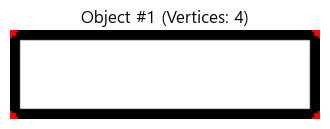

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 읽기 및 전처리
orig = cv.imread('./hi.png')
gray = cv.cvtColor(orig, cv.COLOR_BGR2GRAY)
_, img = cv.threshold(gray, 127, 255, cv.THRESH_BINARY_INV)

# 2. 윤곽선 검출
contours, _ = cv.findContours(img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

target_id = 1

for idx, contour in enumerate(contours):
    if idx + 1 == target_id:
        perimeter = cv.arcLength(contour, True)
        epsilon = 0.03 * perimeter  # 근사 정밀도 조절 (둘레의 3%)
        approx = cv.approxPolyDP(contour, epsilon, True)
        
        vertex_count = len(approx)
        print(f"객체 #{target_id}의 꼭짓점 개수: {vertex_count}개")
        print("꼭짓점 좌표 목록:\n", approx.reshape(-1, 2))

        x, y, w, h = cv.boundingRect(contour)
        cropped_orig = orig[y:y+h, x:x+w].copy()
        
        for point in approx:
            px, py = point[0]
            cv.circle(cropped_orig, (px - x, py - y), 3, (0, 0, 255), -1)

        cropped_rgb = cv.cvtColor(cropped_orig, cv.COLOR_BGR2RGB)
        plt.figure(figsize=(4, 4))
        plt.imshow(cropped_rgb)
        plt.title(f'Object #{target_id} (Vertices: {vertex_count})')
        plt.axis('off')
        plt.show()
        break

총 검출된 객체 수: 11개
[객체 #1] 판별 결과: Rectangle
 - 원형도: 0.5380
 - 꼭짓점 개수: 4개
------------------------------
[객체 #2] 판별 결과: Triangle
 - 원형도: 0.5549
 - 꼭짓점 개수: 3개
------------------------------
[객체 #3] 판별 결과: Rectangle
 - 원형도: 0.5503
 - 꼭짓점 개수: 4개
------------------------------
[객체 #4] 판별 결과: Rectangle
 - 원형도: 0.5786
 - 꼭짓점 개수: 4개
------------------------------
[객체 #5] 판별 결과: Rectangle
 - 원형도: 0.4731
 - 꼭짓점 개수: 4개
------------------------------
[객체 #6] 판별 결과: Rectangle
 - 원형도: 0.5274
 - 꼭짓점 개수: 4개
------------------------------
[객체 #7] 판별 결과: Rectangle
 - 원형도: 0.3970
 - 꼭짓점 개수: 4개
------------------------------
[객체 #8] 판별 결과: Circle
 - 원형도: 0.8937
------------------------------
[객체 #9] 판별 결과: Rectangle
 - 원형도: 0.4453
 - 꼭짓점 개수: 4개
------------------------------
[객체 #10] 판별 결과: Rectangle
 - 원형도: 0.4333
 - 꼭짓점 개수: 4개
------------------------------
[객체 #11] 판별 결과: Rectangle
 - 원형도: 0.4477
 - 꼭짓점 개수: 4개
------------------------------


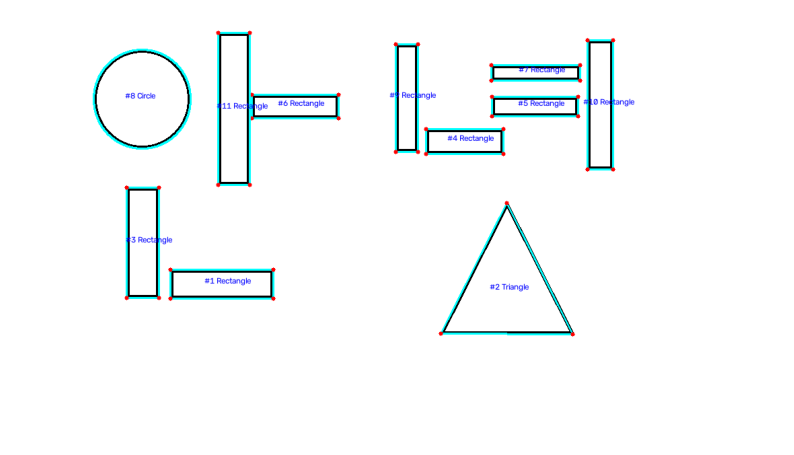

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 읽기 및 전처리
orig = cv.imread('./hi.png')

if orig is None:
    print("이미지를 불러올 수 없습니다.")
    exit()

#색 반전
gray = cv.cvtColor(orig, cv.COLOR_BGR2GRAY)
_, img = cv.threshold(gray, 127, 255, cv.THRESH_BINARY_INV)

#윤관석 뽑아내기
contours, _ = cv.findContours(img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

result_img = orig.copy()

print(f"총 검출된 객체 수: {len(contours)}개\n" + "="*50)

#전체 객체 순환
for idx, contour in enumerate(contours):
    area = cv.contourArea(contour)
    if area < 10:  # 노이즈 스킵
        continue

    perimeter = cv.arcLength(contour, True)
    
#원형도 계산식
    roundness = (4.0 * np.pi * area) / (perimeter * perimeter) if perimeter > 0 else 0
    
#원형도 계산시 0.8이상은 원으로 판별~
    if roundness >= 0.80:
        shape_type = "Circle"
        vertex_count = 0  # 원은 꼭짓점 무의미
        approx = contour  # 원본 윤곽선 유지
    else:
        #다각형 계산을 통해서 각각 객체의 꼭짓점 갯수 찾아내기
        epsilon = 0.03 * perimeter  # 둘레의 3% 근사
        approx = cv.approxPolyDP(contour, epsilon, True)
        vertex_count = len(approx)

        # 꼭짓점 개수 기반 도형 판별
        if vertex_count == 3:
            shape_type = "Triangle"
        elif vertex_count == 4:
            shape_type = "Rectangle"
        elif vertex_count == 5:
            shape_type = "Pentagon"
        elif vertex_count == 6:
            shape_type = "Hexagon"
        else:
            shape_type = f"Polygon({vertex_count})"

    # 중심 좌표 구하기
    m = cv.moments(contour)
    cx, cy = (int(m['m10'] / m['m00']), int(m['m01'] / m['m00'])) if m['m00'] != 0 else (0, 0)

    # 콘솔 출력
    print(f"[객체 #{idx+1}] 판별 결과: {shape_type}")
    print(f" - 원형도: {roundness:.4f}")
    if shape_type != "Circle":
        print(f" - 꼭짓점 개수: {vertex_count}개")
    print("-" * 30)

    cv.drawContours(result_img, [approx], -1, (255, 255, 0), 2)

    #원 제외하고 꼭짓점에 점찍기
    if shape_type != "Circle":
        for point in approx:
            px, py = point[0]
            cv.circle(result_img, (px, py), 3, (0, 0, 255), -1)

    # 객체 위치에 라벨 텍스트 표기
    label = f"#{idx+1} {shape_type}"
    cv.putText(result_img, label, (cx - 25, cy),
               cv.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

# 4. Matplotlib 결과 출력
result_rgb = cv.cvtColor(result_img, cv.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(result_rgb)
plt.axis('off')
plt.show()

In [3]:
import pandas as pd
pd.__version__

'2.2.3'